> **Nota sobre los datos de Get on Board:** Los datos de Get on Board se incluyen solo como agregados por los términos de su API pública; el cálculo completo está en el repositorio de GitHub.

# Mercado Laboral y Salarios en Tecnología (Chile y Latinoamérica 2024–2026)
### Certificado Profesional de Análisis de Datos de Google • Caso Práctico
*Caso de estudio con cliente y partes interesadas simulados (ejercicio académico)*

**Autor:** Manuel Yáñez Orellana  
**Rol:** Analista de Datos  
**Patrocinadores Simulados:** Consultora de RRHH Tech & Academia de Formación Digital (Chile)  
**Versión del Estudio:** v1.13.9 (2026-11-22)  
**Trazabilidad:** [Tablero en Tableau Public](https://public.tableau.com/app/profile/manuel.y.ez/viz/MercadoTechChileyLatAm2024-2026/1_Brechadehabilidadesysalarios) | [Dataset agregado en Kaggle](https://www.kaggle.com/datasets/manuelyanezorellana/mercado-tech-chile-y-latam-2024-2026)

---

## Resumen Ejecutivo y Marco de Negocio
Este cuaderno ejecuta el análisis integral del talento tech en Chile y Latinoamérica a partir de **4 poblaciones independientes** (72.797 registros crudos validados):
1. **Get on Board (2026):** Demanda laboral activa en Chile y vacantes remotas sin país declarado (corte al 2026-11-10, 679 ofertas en alcance, 235 salarios válidos).
2. **Stack Overflow Developer Survey (2024):** Adopción de habilidades y salarios de 3.074 desarrolladores encuestados en 19 países de LatAm (133 en Chile; 1.341 salarios válidos).
3. **Data Science Salaries (2020–2024):** Serie histórica internacional de roles de datos (6.599 registros; 5.305 residentes en EE.UU.).
4. **INE ESI 2025 (Chile):** Línea base oficial nacional de ingresos laborales en Chile ($680.000 CLP / $701 USD mediana mensual).

**Regla de Oro Metodológica:** Ninguna población se fusiona a nivel de fila ni se promedian juntas fuentes con marcos de muestreo disímiles. Toda conclusión cuantitativa exige suficiencia muestral ($N \ge 30$, CLT).

In [1]:
import os
from pathlib import Path
import glob
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

# Estilo gráfico y configuración de visualización accesible
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True

# Detección determinista de rutas según el entorno (Kaggle, prueba o repositorio local)
SO_FILE = "StackOverflow_LatAm_2024_20261111_v01_clean.csv"
KAGGLE_CANDIDATES = glob.glob(f"/kaggle/input/**/{SO_FILE}", recursive=True)
ENV_DATA = os.environ.get("KAGGLE_DATA_DIR")

if ENV_DATA and Path(ENV_DATA).exists():
    DATA_DIR = Path(ENV_DATA)
    print(f"Ambiente de prueba configurado. Directorio de datos: {DATA_DIR}")
elif KAGGLE_CANDIDATES:
    DATA_DIR = Path(KAGGLE_CANDIDATES[0]).parent
    print(f"Ambiente Kaggle detectado. Directorio de datos: {DATA_DIR}")
elif Path("descargas/kaggle_dataset").exists():
    DATA_DIR = Path("descargas/kaggle_dataset")
    print(f"Ambiente local detectado. Directorio de datos: {DATA_DIR}")
elif Path("../descargas/kaggle_dataset").exists():
    DATA_DIR = Path("../descargas/kaggle_dataset")
    print(f"Ambiente local alternativo detectado. Directorio de datos: {DATA_DIR}")
else:
    DATA_DIR = Path(".")
    print(f"Directorio de datos por defecto: {DATA_DIR}")

# Montos con el signo menos antes del "$", miles con punto y decimales con coma.
# Es copia de dinero() en scripts/formato_dinero.py del repositorio de GitHub.
def dinero(v, dec=0):
    v = float(v)
    if dec == 0:
        n = int(round(abs(v)))
        cuerpo = f"{n:,}".replace(",", ".")
        cero = n == 0
    else:
        cuerpo = f"{abs(v):,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
        cero = cuerpo.strip("0,.") == ""
    signo = "-" if v < 0 and not cero else ""
    return f"{signo}${cuerpo}"

Ambiente local detectado. Directorio de datos: descargas/kaggle_dataset


In [2]:
# Ingesta del paquete de datos para Kaggle (Fase 2: Preparar • Cursos 3 y 4)
# Datos limpios de encuestas y fuentes de referencia:
so_lat = pd.read_csv(DATA_DIR / "StackOverflow_LatAm_2024_20261111_v01_clean.csv")
so_tec = pd.read_csv(DATA_DIR / "StackOverflow_Tecnologias_2024_20261111_v01_clean.csv")
dss    = pd.read_csv(DATA_DIR / "DataScienceSalaries_2020_2024_20261111_v01_clean.csv")
ine    = pd.read_csv(DATA_DIR / "INE_ESI_2025_ReferenciaNacional_20261111_v01_clean.csv")

# Agregados oficiales de Get on Board (cumpliendo TOS API sección 7.1: sin extremos mín/máx, niveles de seniority agrupados y, con N < 15, solo el N):
gob_ctrl       = pd.read_csv(DATA_DIR / "gob_agregado_control_integridad.csv")
gob_tec        = pd.read_csv(DATA_DIR / "gob_agregado_tecnologias.csv")
gob_bandas_cl  = pd.read_csv(DATA_DIR / "gob_agregado_bandas_chile_local.csv")
gob_bandas_rem = pd.read_csv(DATA_DIR / "gob_agregado_bandas_remoto_sin_pais.csv")
gob_mod        = pd.read_csv(DATA_DIR / "gob_agregado_modalidad.csv")
gob_mod_ine    = pd.read_csv(DATA_DIR / "gob_agregado_modalidad_vs_ine.csv")

# Conteo total dinámico de Get on Board desde el archivo de agregados (sin números tecleados)
gob_total_vacantes = int(gob_ctrl[gob_ctrl['poblacion'].str.contains('Get on Board', na=False)]['registros_unicos'].iloc[0])

print(f"Stack Overflow LatAm:  {len(so_lat):,} filas | Tecnologías: {len(so_tec):,} filas")
print(f"Data Science Salaries: {len(dss):,} filas")
print(f"Get on Board (total vacantes evaluadas en estudio): {gob_total_vacantes:,} vacantes")
mediana_ine = int(ine[ine['indicador'] == 'Ingreso Mediano Nacional Ocupados']['monto_clp_mensual'].iloc[0])
mediana_ine_usd = round(mediana_ine / 969.8, 2)
print(f"INE ESI 2025 Nacional = {mediana_ine:,} CLP ({mediana_ine_usd:,} USD aprox.)")

Stack Overflow LatAm:  3,074 filas | Tecnologías: 31,759 filas
Data Science Salaries: 6,599 filas
Get on Board (total vacantes evaluadas en estudio): 679 vacantes
INE ESI 2025 Nacional = 680,000 CLP (701.18 USD aprox.)


## 1. Arquitectura Relacional en SQLite (Fase 4 • Curso 5)
Carga de las tablas en SQLite en memoria para consultar las tablas normalizadas (Ancho + Largo).
Se controlan las uniones 1:N mediante `LEFT JOIN` y `COUNT(DISTINCT ...)` para evitar la duplicación de salarios y sesgos en denominadores.

In [3]:
conn = sqlite3.connect(":memory:")
so_lat.to_sql("so_encuestados", conn, index=False)
so_tec.to_sql("so_tecnologias", conn, index=False)
dss.to_sql("dss", conn, index=False)
ine.to_sql("ine", conn, index=False)

# Control de integridad de unión 1:N en Stack Overflow
q_so_integridad = """
SELECT 
    'Stack Overflow 2024 (LatAm 19)' AS poblacion,
    COUNT(DISTINCT e.ResponseId) AS total_encuestados_unicos,
    COUNT(t.ResponseId) AS filas_expandidas_1_n,
    ROUND(AVG(e.salario_mensual_usd), 2) AS media_correcta_sin_duplicacion
FROM so_encuestados e
LEFT JOIN so_tecnologias t ON e.ResponseId = t.ResponseId
WHERE e.salario_valido_flag = 1
GROUP BY 1;
"""
df_so_int = pd.read_sql(q_so_integridad, conn)

print("=== CONTROL DE INTEGRIDAD RELACIONAL (TABLA DE CONTROL DE AGREGADOS) ===")
display(gob_ctrl)
print("=== VERIFICACIÓN DE INTEGRIDAD JOIN 1:N EN STACK OVERFLOW ===")
display(df_so_int)

=== CONTROL DE INTEGRIDAD RELACIONAL (TABLA DE CONTROL DE AGREGADOS) ===


,poblacion,registros_unicos,filas_expandidas_1aN,registros_sin_tecnologia_coalesce,media_con_duplicacion_join_1aN
0,Get on Board 2026 (Chile/Remoto),679,1749,165,2928.93
1,Stack Overflow 2024 (LatAm 19),3074,31759,72,3455.35


=== VERIFICACIÓN DE INTEGRIDAD JOIN 1:N EN STACK OVERFLOW ===


,poblacion,total_encuestados_unicos,filas_expandidas_1_n,media_correcta_sin_duplicacion
0,Stack Overflow 2024 (LatAm 19),1341,14528,3455.35


## 2. Pregunta de Investigación 1 (P1): Demanda vs. Adopción Tecnológica
**Pregunta de Negocio (P1):** *¿Cuáles son las tecnologías más demandadas por los empleadores tech en Chile y qué brechas existen frente a las habilidades que declaran los profesionales?*

**Hallazgo Clave (PASO 4.1):** 3 tecnologías superan el 20% de las ofertas en Get on Board: SQL (32,8%, 223), AWS (30,0%, 204) y Python (28,4%, 193). En plataformas Cloud, solo AWS supera el umbral del 20%, mientras que Google Cloud (17,23%, 117) y Microsoft Azure (17,1%, 116) se sitúan por debajo del umbral estratégico.

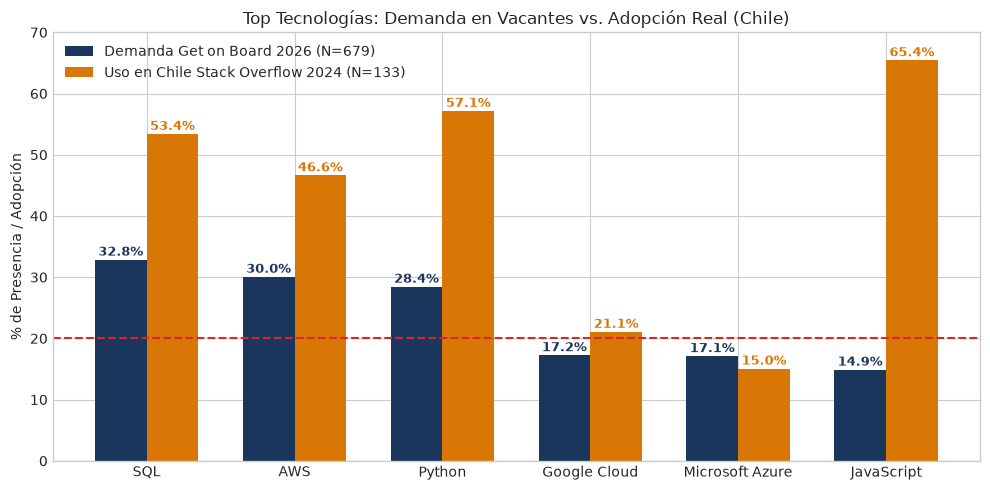

In [4]:
# Consulta dinámica de adopción en Chile desde Stack Overflow en SQLite
q_so_tech = """
SELECT 
    tecnologia,
    ROUND(COUNT(DISTINCT ResponseId) * 100.0 / (SELECT COUNT(DISTINCT ResponseId) FROM so_encuestados WHERE pais = 'Chile'), 2) AS pct_so_chile
FROM so_tecnologias
WHERE pais = 'Chile'
GROUP BY tecnologia;
"""
df_so_tech = pd.read_sql(q_so_tech, conn)

# Tecnologías prioritarias del análisis
tech_focus = ['SQL', 'AWS', 'Python', 'Microsoft Azure', 'Google Cloud', 'JavaScript']

# Cruce con agregados de demanda de Get on Board
df_p1 = gob_tec[gob_tec['tecnologia'].isin(tech_focus)].copy()
df_p1['pct_demanda_gob'] = df_p1['pct_demanda_gob_total']
df_p1 = df_p1.merge(df_so_tech, on='tecnologia', how='left')
df_p1['pct_so_chile'] = df_p1['pct_so_chile'].fillna(df_p1.get('pct_adopcion_chile', 0))
df_p1 = df_p1.sort_values('pct_demanda_gob', ascending=False).reset_index(drop=True)

n_so_chile = len(so_lat[so_lat['pais'] == 'Chile'])

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_p1))
width = 0.35

rects1 = ax.bar(x - width/2, df_p1['pct_demanda_gob'], width, label=f'Demanda Get on Board 2026 (N={gob_total_vacantes})', color='#1B365D')
rects2 = ax.bar(x + width/2, df_p1['pct_so_chile'], width, label=f'Uso en Chile Stack Overflow 2024 (N={n_so_chile})', color='#D97706')

ax.set_ylabel('% de Presencia / Adopción')
ax.set_title('Top Tecnologías: Demanda en Vacantes vs. Adopción Real (Chile)')
ax.set_xticks(x)
ax.set_xticklabels(df_p1['tecnologia'])
ax.legend()
ax.axhline(20.0, color='#DC2626', linestyle='--', linewidth=1.5, label='Umbral Mínimo de Presencia (20%)')

for r in rects1:
    h = r.get_height()
    ax.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', fontsize=9, color='#1B365D', fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', fontsize=9, color='#D97706', fontweight='bold')

ax.set_ylim(0, 70)
plt.show()

## 3. Pregunta de Investigación 2 (P2): Progresión Salarial y Bandas de Seniority
**Pregunta de Negocio (P2):** *¿Cuál es la estructura salarial por nivel de experiencia y en qué tramo ocurre el mayor salto porcentual?*

**Hallazgo Clave (PASO 4.2):** En Chile Local (Get on Board 2026), la mediana salarial es $2.250 USD en Semi-Senior (N=65, p25 $2.000, p75 $2.500) y $2.825 USD en Senior + Lead (N=58, p25 $2.200, p75 $3.750): un salto de +25,6% en mediana. En este paquete los niveles de Get on Board se publican agrupados (Chile Local: Junior + Trainee, Semi-Senior y Senior + Lead; ofertas remotas sin país declarado: Junior + Trainee + Semi-Senior y Senior + Lead) y los grupos con N < 15 muestran solo su N, para que ningún grupo chico pueda deducirse cruzando tablas. En Stack Overflow Chile agregado (46), la mediana es $3.064 USD (~$2.971.031 CLP).

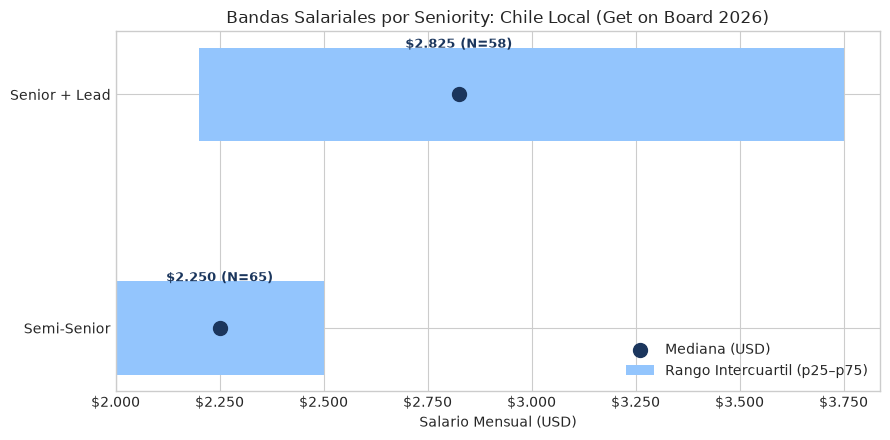

In [5]:
# Visualización de bandas salariales para Chile Local desde agregados oficiales
niveles = ['Semi-Senior', 'Senior + Lead']
cl_plot = gob_bandas_cl.set_index('seniority_nivel').reindex(niveles).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(cl_plot))
ax.barh(y, cl_plot['p75_usd'] - cl_plot['p25_usd'], left=cl_plot['p25_usd'], height=0.4, color='#93C5FD', label='Rango Intercuartil (p25–p75)')
ax.scatter(cl_plot['mediana_usd'], y, color='#1B365D', s=100, zorder=5, label='Mediana (USD)')

for idx, row in cl_plot.iterrows():
    y_pos = y[idx]
    ax.text(row['mediana_usd'], y_pos + 0.2, f"{dinero(row['mediana_usd'])} (N={int(row['n'])})",
            ha='center', fontweight='bold', color='#1B365D', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(cl_plot['seniority_nivel'])
ax.set_xlabel('Salario Mensual (USD)')
ax.set_title('Bandas Salariales por Seniority: Chile Local (Get on Board 2026)')
ax.legend(loc='lower right')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: dinero(x)))
plt.show()

## 4. Pregunta de Investigación 3 (P3): Modalidad, Alcance y Comparación INE
**Pregunta de Negocio (P3):** *¿Existe una prima salarial estadísticamente atribuible al trabajo remoto frente al presencial en Chile?*

**Hallazgo Clave (PASO 4.3):** Comparando solo cargos Senior + Lead, las ofertas remotas sin país declarado tienen mediana $3.800 frente a $2.825 en Chile Local (diferencia +$975 USD, IC 95% bootstrap [$500, $1.600]): la diferencia es concluyente, así que la mayor proporción de cargos Senior y Lead en remoto no alcanza para explicar toda la brecha. Modalidad y alcance no se pueden separar con estos datos, y no se sabe si las ofertas remotas admiten residentes en Chile. Frente a la mediana nacional del INE ESI 2025 ($680.000 CLP / $701 USD), los cargos Semi-Senior en Chile Local ($2.250 USD mediana) representan 3,21x la mediana del INE: la superan en +220,9%.

=== COMPOSICIÓN MODALIDAD X SENIORITY (GOB) ===


,modalidad_grupo,n_salarios_validos,media_mensual_usd,pct_senior_lead,pct_junior_trainee_semi_senior,pct_alcance_remoto_global
0,Remoto Local,45,3814.44,68.9,31.1,100.0
1,Remoto Total,53,3106.60,58.5,41.5,100.0
2,Híbrido,103,2561.65,43.7,56.3,0.0
3,Presencial,34,2269.12,38.2,61.8,0.0


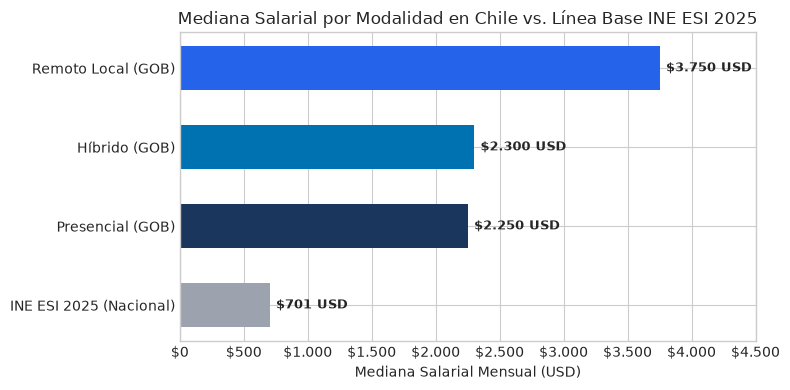

In [6]:
# Composición de Modalidad en Get on Board (agregados oficiales)
print("=== COMPOSICIÓN MODALIDAD X SENIORITY (GOB) ===")
display(gob_mod)

med_cl_local = float(gob_mod_ine[gob_mod_ine['segmento'] == 'Presencial']['mediana_usd'].iloc[0])
med_hibrido  = float(gob_mod_ine[gob_mod_ine['segmento'] == 'Híbrido']['mediana_usd'].iloc[0])
med_rem_loc  = float(gob_mod_ine[gob_mod_ine['segmento'] == 'Remoto Local']['mediana_usd'].iloc[0])

fig, ax = plt.subplots(figsize=(8, 4))
bar_data = pd.Series({
    'INE ESI 2025 (Nacional)': mediana_ine_usd,
    'Presencial (GOB)': med_cl_local,
    'Híbrido (GOB)': med_hibrido,
    'Remoto Local (GOB)': med_rem_loc
})

bars = ax.barh(bar_data.index, bar_data.values, color=['#9CA3AF', '#1B365D', '#0072B2', '#2563EB'], height=0.55)
for b in bars:
    w = b.get_width()
    ax.text(w + 50, b.get_y() + b.get_height()/2, f"{dinero(w)} USD", va='center', fontweight='bold', fontsize=9)

ax.set_xlim(0, 4500)
ax.set_xlabel('Mediana Salarial Mensual (USD)')
ax.set_title('Mediana Salarial por Modalidad en Chile vs. Línea Base INE ESI 2025')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: dinero(x)))
plt.show()

## 5. Pregunta de Investigación 4 (P4): Posicionamiento Regional y Serie Temporal
**Pregunta de Negocio (P4):** *¿Cómo se posiciona Chile en remuneraciones respecto al resto de Latinoamérica bajo suficiencia muestral N >= 30 y qué tendencias refleja la serie temporal internacional?*

**Hallazgo Clave (PASO 4.4):** En Latinoamérica (Stack Overflow 2024, N ≥ 30), Uruguay registra la mediana más alta ($6.416 USD, 36). Chile ($3.064 USD, 46) se sitúa en un grupo estadísticamente no diferenciable frente a Argentina ($2.958 USD, 124), México ($2.633 USD, 164) y Colombia ($2.500 USD, 83) (todos los intervalos de confianza bootstrap del 95% de las diferencias con Chile incluyen el 0). Brasil registra $2.020 USD (673) y Venezuela $1.000 USD (33). En Data Science Salaries (residentes en EE.UU.), la mediana pasó de $9.917 USD en 2020 (28 < 30) a $12.500 USD en 2023 (3854) y $11.673 USD en 2024 (506).

Cargando matriz TLC desde: descargas/kaggle_dataset/Matriz_TLC_19_Paises_LatAm.csv


,pais,n_sal,cumple_n30,med_usd,ic95_mediana_inf_usd,ic95_mediana_sup_usd
0,Brasil,673,True,2020.25,1864.83,2148.08
1,México,164,True,2632.54,2282.12,2696.80
2,Argentina,124,True,2958.34,2309.42,3939.88
3,Colombia,83,True,2500.00,1471.92,3616.75
4,Chile,46,True,3063.55,2382.95,3700.75
5,Uruguay,36,True,6416.41,5625.00,7710.42
6,Perú,29,False,2200.50,NaN,NaN
7,Venezuela,33,True,1000.00,666.67,1666.67
8,Ecuador,25,False,1500.00,NaN,NaN
9,Costa Rica,20,False,6096.04,NaN,NaN


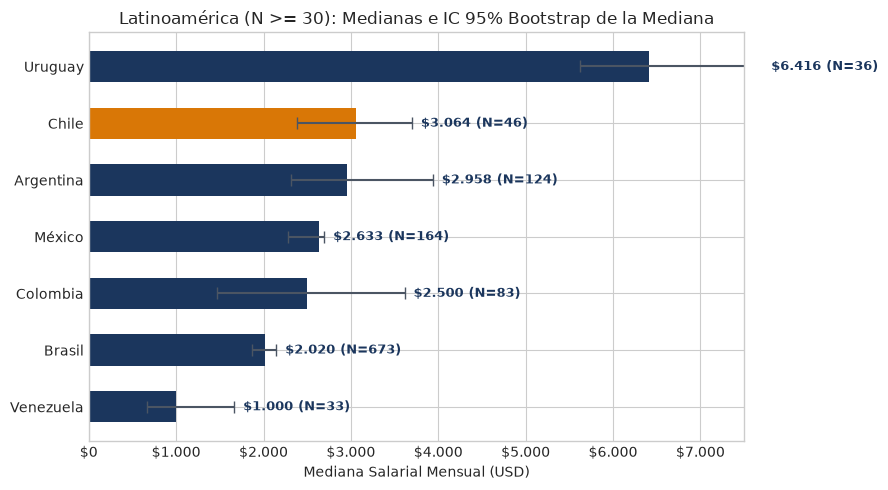

In [7]:
# Carga de Matriz TLC de 19 Países preparada con IC 95% bootstrap desde DATA_DIR
tlc_file = DATA_DIR / "Matriz_TLC_19_Paises_LatAm.csv"

if tlc_file.exists():
    df_tlc = pd.read_csv(tlc_file)
    print(f"Cargando matriz TLC desde: {tlc_file}")
    display(df_tlc[['pais', 'n_sal', 'cumple_n30', 'med_usd', 'ic95_mediana_inf_usd', 'ic95_mediana_sup_usd']].head(10))
else:
    raise FileNotFoundError(f"Archivo Matriz_TLC_19_Paises_LatAm.csv no encontrado en {DATA_DIR}")

df_p4_plot = df_tlc[df_tlc['cumple_n30'] == True].sort_values('med_usd', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(df_p4_plot))
xerr_inf = df_p4_plot['med_usd'] - df_p4_plot['ic95_mediana_inf_usd']
xerr_sup = df_p4_plot['ic95_mediana_sup_usd'] - df_p4_plot['med_usd']

colors_latam = ['#D97706' if p == 'Chile' else '#1B365D' for p in df_p4_plot['pais']]
ax.barh(y_pos, df_p4_plot['med_usd'], xerr=[xerr_inf, xerr_sup], capsize=4, color=colors_latam, height=0.55, 
        error_kw={'elinewidth': 1.5, 'ecolor': '#4B5563'})

for idx, row in df_p4_plot.iterrows():
    ax.text(row['ic95_mediana_sup_usd'] + 100, idx, f"{dinero(row['med_usd'])} (N={int(row['n_sal'])})",
            va='center', fontsize=9, fontweight='bold', color='#1B365D')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_p4_plot['pais'])
ax.set_xlabel('Mediana Salarial Mensual (USD)')
ax.set_title('Latinoamérica (N >= 30): Medianas e IC 95% Bootstrap de la Mediana')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: dinero(x)))
ax.set_xlim(0, 7500)
plt.show()

## 6. Profundización Q11: Matriz Volumen vs. Compensación y Efecto Cloud
**Análisis:** Al cruzar el volumen de demanda con la remuneración observada en Get on Board dentro de los cargos Senior + Lead, se evalúa si el conocimiento de Cloud confiere una prima concluyente.

**Hallazgo Clave (PASO 4.5):** Dentro de los cargos Senior + Lead de Get on Board, las vacantes con tecnologías Cloud tienen mediana $3.750 frente a $3.125 USD sin Cloud (diferencia observada +$625 USD). La tabla siguiente muestra, para AWS, Microsoft Azure y Google Cloud frente a SQL dentro de Senior + Lead, el intervalo de confianza del 95% de cada diferencia y si es concluyente.

In [8]:
# Inferencia Bootstrap de Diferencias Pareadas (IC 95%) leída desde DATA_DIR
ic_file = DATA_DIR / "gob_agregado_ic_diferencias.csv"

if ic_file.exists():
    df_ic = pd.read_csv(ic_file)
    print("=== INTERVALOS DE CONFIANZA BOOTSTRAP DEL 95% PARA DIFERENCIAS DE MEDIANAS ===")
    display(df_ic[['comparacion', 'diferencia_observada_usd', 'ic95_inf_usd', 'ic95_sup_usd', 'concluyente']])
else:
    raise FileNotFoundError(f"Archivo gob_agregado_ic_diferencias.csv no encontrado en {DATA_DIR}")

=== INTERVALOS DE CONFIANZA BOOTSTRAP DEL 95% PARA DIFERENCIAS DE MEDIANAS ===


,comparacion,diferencia_observada_usd,ic95_inf_usd,ic95_sup_usd,concluyente
0,Chile − Argentina (SO LatAm),105.21,-1121.88,1114.25,False
1,Chile − México (SO LatAm),431.01,-267.34,1183.83,False
2,Chile − Colombia (SO LatAm),563.55,-802.21,1840.67,False
3,Senior + Lead Remoto sin país − Senior + Lead ...,975.00,500.00,1600.00,True
4,AWS − SQL (Senior + Lead GOB),675.00,-275.00,1275.00,False
5,Microsoft Azure − SQL (Senior + Lead GOB),675.00,-250.00,1400.00,False
6,Google Cloud − SQL (Senior + Lead GOB),675.00,-725.00,1275.00,False


## 7. Plan de Acción y Tabla de Recomendaciones Estratégicas (PASO 4.6)
A partir de los hallazgos estadísticamente fundamentados, se adopta una matriz de implementación Qué / Quién / Cuándo / KPI unificada para todo el portafolio:

| # | Qué hay que hacer (Acción concreta) | Quién debería hacerlo | Cuándo (Plazo) | Indicador Clave de Rendimiento (KPI) |
|---|---|---|---|---|
| **1** | Alinear currículo formativo a las 3 tecnologías líderes (SQL, AWS, Python) con electivos en cloud computing. | Academia de formación digital | Trimestre 1 (Q1) | Porcentaje de cobertura de tecnologías top en sílabos (meta: ≥ 80% sobre las 3 tecnologías ≥ 20%). |
| **2** | Calibrar bandas salariales diferenciando explícitamente entre vacantes de Chile Local y Remoto sin país declarado. | Consultora de RRHH tech | Trimestre 1 (Q1) | Tasa de ofertas con salario publicado clasificadas por alcance local vs remoto (meta: 100%). |
| **3** | Diseñar rutas de transición y nivelación técnica de Semi-Senior a Senior con foco en diseño de sistemas y arquitectura cloud. | Academia y Consultora en conjunto | Trimestre 2 (Q2) | Brecha porcentual observada entre Semi-Senior y Senior + Lead (+25,6% en Chile Local). |

---
*Fin del cuaderno analítico reproducible.*